# 1. Arquitetura

A rede neural implementada possui duas camadas: uma camada oculta com função de ativação sigmoide e uma camada de saída linear.

\[
x\ (64\times1000)\rightarrow w_1\ (1000\times100)\rightarrow
\text{sigmoide}\rightarrow h\ (64\times100)\rightarrow
w_2\ (100\times10)\rightarrow \hat{y}\ (64\times10)
\]

| Camada | Entrada | Saída | Pesos | Ativação | Parâmetros |
|---|---:|---:|---|---|---:|
| Oculta | 1000 | 100 | \(w_1\) (1000×100) | Sigmoide | 100.000 |
| Saída | 100 | 10 | \(w_2\) (100×10) | Linear | 1.000 |
| **Total** | | | | | **101.000** |

**Configurações utilizadas**

| Parâmetro | Valor |
|---|---|
| Amostras (\(N\)) | 64, lote completo |
| \(D_{in}/H/D_{out}\) | 1000 / 100 / 10 |
| Perda | Soma dos erros quadráticos |
| Taxa de aprendizado | \(1e-4\) |
| Iterações | 2000 |
| Inicialização | `randn` (normal padrão) |
| Dados | Aleatórios (\(x\) e \(y\)) |
| Semente | 42 |
| Bias | Não |

# 2. Forward pass e perda

Na etapa de propagação direta (*forward pass*), a entrada é multiplicada pelos pesos da primeira camada. Em seguida, aplica-se a função sigmoide para obter a camada oculta. Por fim, a saída é calculada pela multiplicação da camada oculta pelos pesos da segunda camada.

\[
z_1=xw_1,\qquad
h=\sigma(z_1)=\frac{1}{1+e^{-z_1}},\qquad
\hat{y}=hw_2
\]

A função de perda utilizada foi a soma dos erros quadráticos entre as saídas previstas e os valores esperados:

\[
L=\sum_n\sum_k(\hat{y}_{nk}-y_{nk})^2
\]

# 3. Gradientes (backward pass)

Os gradientes são calculados no sentido contrário ao da propagação direta, utilizando a regra da cadeia.

| Gradiente | Fórmula | Shape | Linha |
|---|---|---:|---:|
| \(\partial L/\partial\hat{y}\) | \(2(\hat{y}-y)\) | 64×10 | 14 |
| \(\partial L/\partial w_2\) | \(h^T\cdot\partial L/\partial\hat{y}\) | 100×10 | 15 |
| \(\partial L/\partial h\) | \(\partial L/\partial\hat{y}\cdot w_2^T\) | 64×100 | 16 |
| \(\partial L/\partial z_1\) | \(\partial L/\partial h\odot h\odot(1-h)\) | 64×100 | 17 |
| \(\partial L/\partial w_1\) | \(x^T\cdot\partial L/\partial z_1\) | 1000×100 | 17 |

A derivada da função sigmoide é:

\[
\sigma'(z)=h(1-h)
\]

A atualização dos pesos é realizada pela regra:

\[
w\leftarrow w-\eta\cdot\frac{\partial L}{\partial w},
\qquad \eta=1e-4
\]

# 4. Ambiente

| Item | Valor |
|---|---|
| Python | 3.13.18 |
| NumPy | 2.4.6 |
| Sistema | Linux, Google Colab |
| Tempo de treino (2000 iterações) | 2,96 s |

# 5. Resultados

## 5.1 Treinamento base

A tabela apresenta a evolução da perda durante o treinamento:

| Iteração | Perda |
|---:|---:|
| 0 | 34.522,55 |
| 10 | 8.966,59 |
| 100 | 2.474,30 |
| 500 | 223,48 |
| 1000 | 47,05 |
| Final | 5,61 |

A redução da perda foi de **99,98%**.

*Figura 1: perda por iteração (escala linear e logarítmica).*

## 5.2 Gradient check

Foi realizado o *gradient check* com \(\varepsilon=1e-5\), utilizando diferença central. O erro relativo é calculado por:

\[
\text{Erro relativo}=
\frac{|g_{ana}-g_{num}|}{\max(|g_{ana}|,|g_{num}|)}
\]

| Peso | Analítico | Numérico | Erro relativo |
|---|---:|---:|---:|
| w1[684,47] | 0,942143 | 0,942143 | 1,3e-07 |
| w1[629,64] | 8,965841 | 8,965841 | 3,6e-08 |
| w1[835,67] | 0,421505 | 0,421505 | 9,1e-07 |
| w1[359,9] | 14,237105 | 14,237105 | 9,2e-09 |
| w1[723,21] | 4,542393 | 4,542394 | 6,9e-08 |
| w2[36,7] | 56,002219 | 56,002220 | 5,7e-09 |
| w2[70,8] | 250,753880 | 250,753880 | 2,3e-10 |
| w2[88,1] | 137,957751 | 137,957750 | 1,8e-09 |
| w2[39,7] | −45,322612 | −45,322612 | 1,3e-08 |
| w2[46,8] | 264,280198 | 264,280198 | 5,8e-11 |

O erro relativo máximo foi de **9,1e-07**.

## 5.3 Norma dos gradientes

| Medida | Início | Fim |
|---|---:|---:|
| \(\|\mathrm{grad}_{w1}\|\) | 5.446,11 | 3,32 |
| \(\|\mathrm{grad}_{w2}\|\) | 11.548,56 | 9,36 |

*Figura 2: norma de Frobenius dos gradientes por iteração (escala log).*

## 5.4 Saturação da sigmoide

| Medida | Valor |
|---|---:|
| Desvio-padrão de \(z_1\) (início) | 31,73 |
| Média de \(\sigma'=h(1-h)\) (início) | 0,0131 |
| Máximo de \(\sigma'\) | 0,25 |
| Fração de \(h<0,01\) ou \(h>0,99\) (início) | 88,3% |
| Fração de \(h<0,01\) ou \(h>0,99\) (fim) | 94,1% |

*Figura 3: histogramas de \(h\) no início e no fim do treino.*

## 5.5 Taxa de aprendizado

| \(\eta\) | Perda final | Resultado |
|---:|---:|---|
| 1e-3 | Não finita | Divergiu |
| 1e-4 | 5,61 | Convergiu |
| 1e-5 | 1.062,49 | Convergiu lentamente |
| 1e-6 | 7.059,15 | Convergiu muito lentamente |

*Figura 4: perda por iteração para cada taxa de aprendizado (a curva de 1e-3 é cortada ao passar de 1e10).*

## 5.6 Tamanho da camada oculta

| \(H\) | Parâmetros | Perda final |
|---:|---:|---:|
| 10 | 10.100 | 502,13 |
| 50 | 50.500 | 148,97 |
| 100 | 101.000 | 5,61 |
| 500 | 505.000 | 1,8e-25 |

*Figura 5: perda por iteração para cada valor de \(H\).*

# 6. Conclusões

- A perda caiu 99,98% em 2000 iterações (34.522,55 → 5,61).
- O *gradient check* validou os gradientes analíticos: erro relativo máximo de 9,1e-07.
- A sigmoide satura desde o início (88,3% dos valores de \(h\)) e termina com 94,1%.
- \(\eta=1e-3\) diverge; \(1e-5\) e \(1e-6\) convergem mais lentamente que \(1e-4\).
- Quanto maior \(H\), menor a perda final de treino.
- Os dados são aleatórios, então a queda da perda indica memorização das 64 amostras, não aprendizado de padrões.


In [ ]:
!python rede_neural_2_camadas.py

{
  "ambiente": {
    "python": "3.13.18",
    "numpy": "2.4.6",
    "sistema": "Linux-6.6.159+-x86_64-with-glibc2.39",
    "seed": 42
  },
  "n_parametros": 101000,
  "treino_base": {
    "loss_inicial": 34522.553725210404,
    "loss_final": 5.607287468551618,
    "reducao_percentual": 99.98375761100067,
    "loss_iter_10": 8966.59408050025,
    "loss_iter_100": 2474.301378886713,
    "loss_iter_500": 223.47794319633817,
    "loss_iter_1000": 47.0526171586431,
    "tempo_s": 3.7140862941741943,
    "norm_g1_inicial": 5446.114884829196,
    "norm_g2_inicial": 11548.557014837132,
    "norm_g1_final": 3.3192428182587532,
    "norm_g2_final": 9.35819743452528
  },
  "gradient_check": [
    {
      "peso": "w1[684,47]",
      "analitico": 0.9421428965996668,
      "numerico": 0.9421430149814113,
      "erro_relativo": 1.2565156524629842e-07
    },
    {
      "peso": "w1[629,64]",
      "analitico": 8.96584064833839,
      "numerico": 8.965840970631689,
      "erro_relativo": 3.59468008254

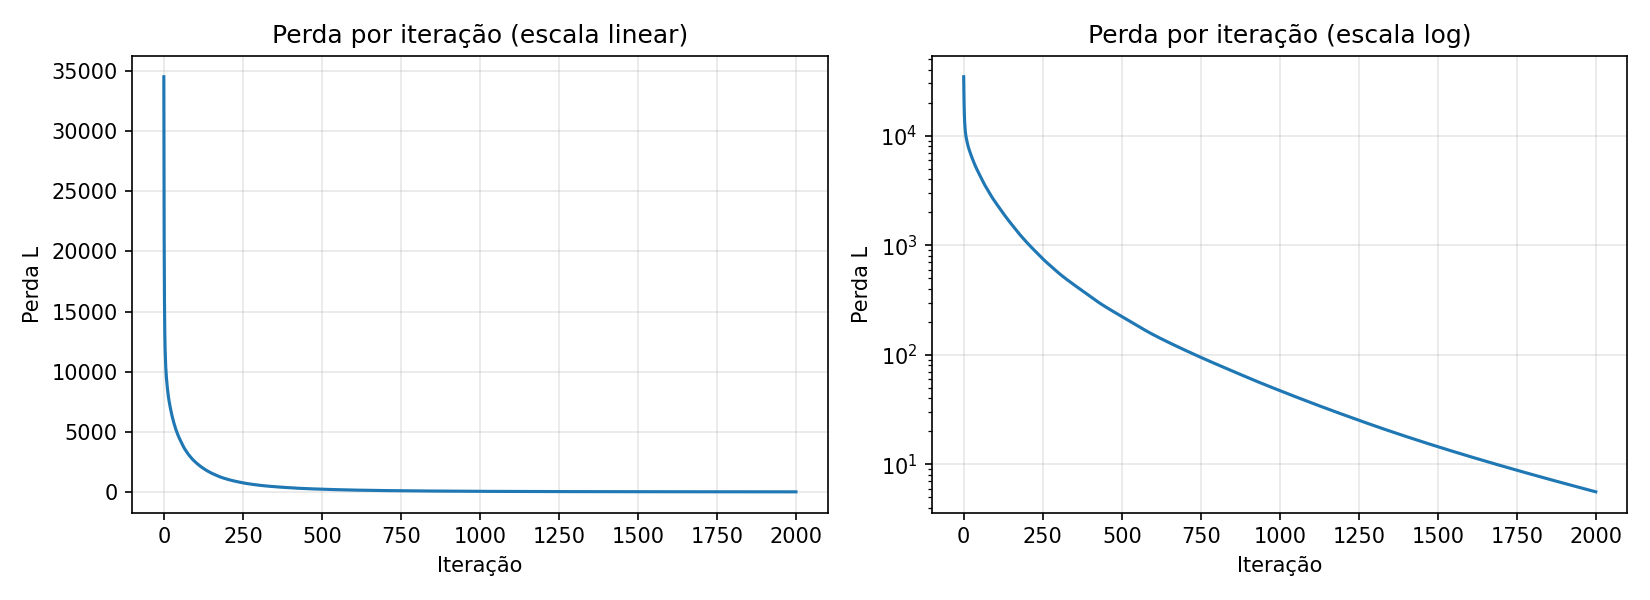

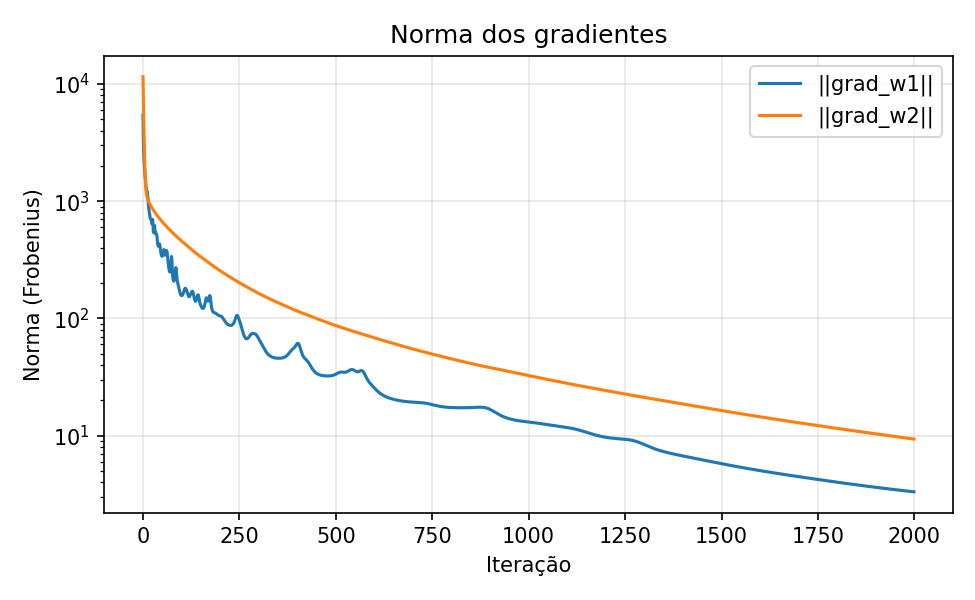

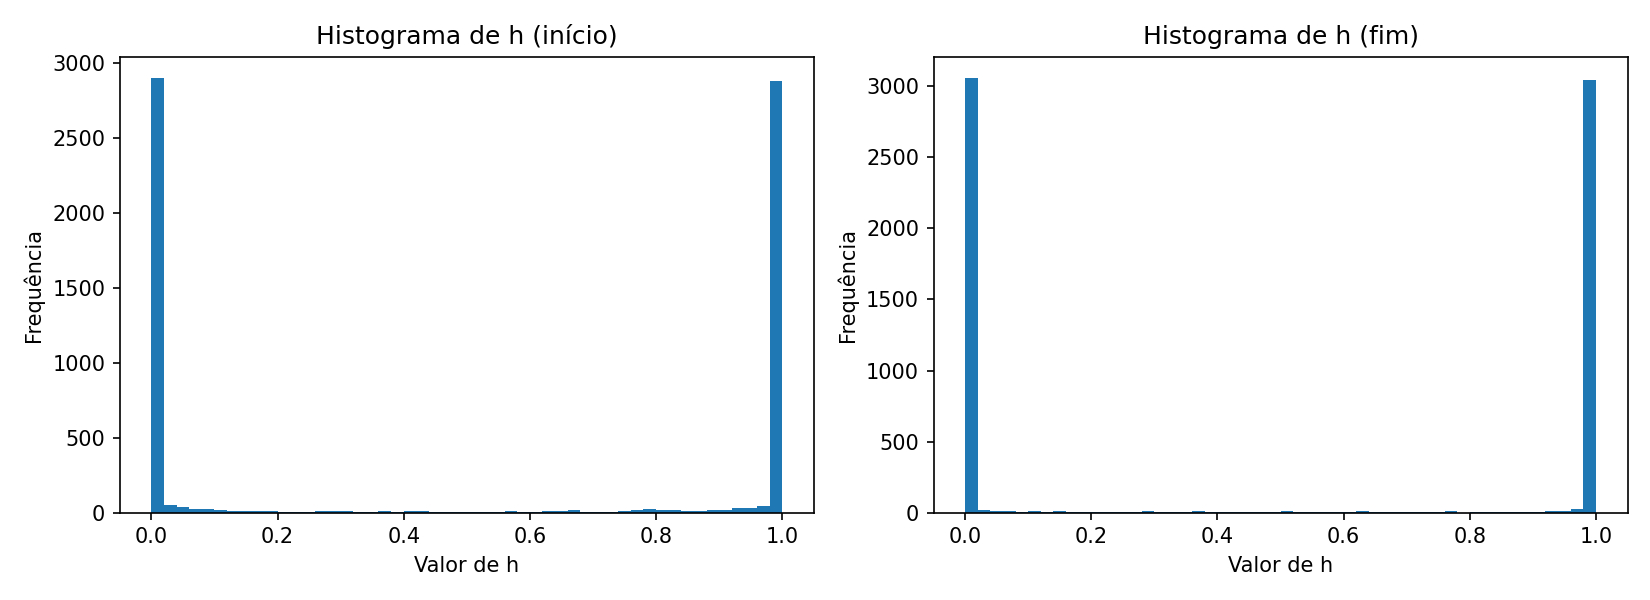

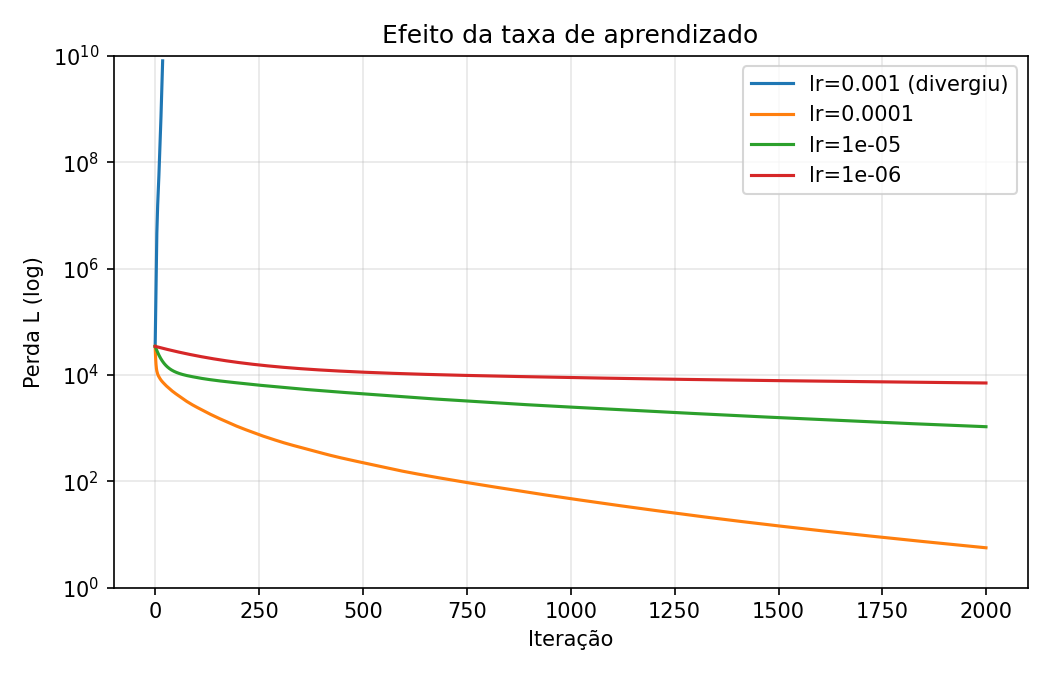

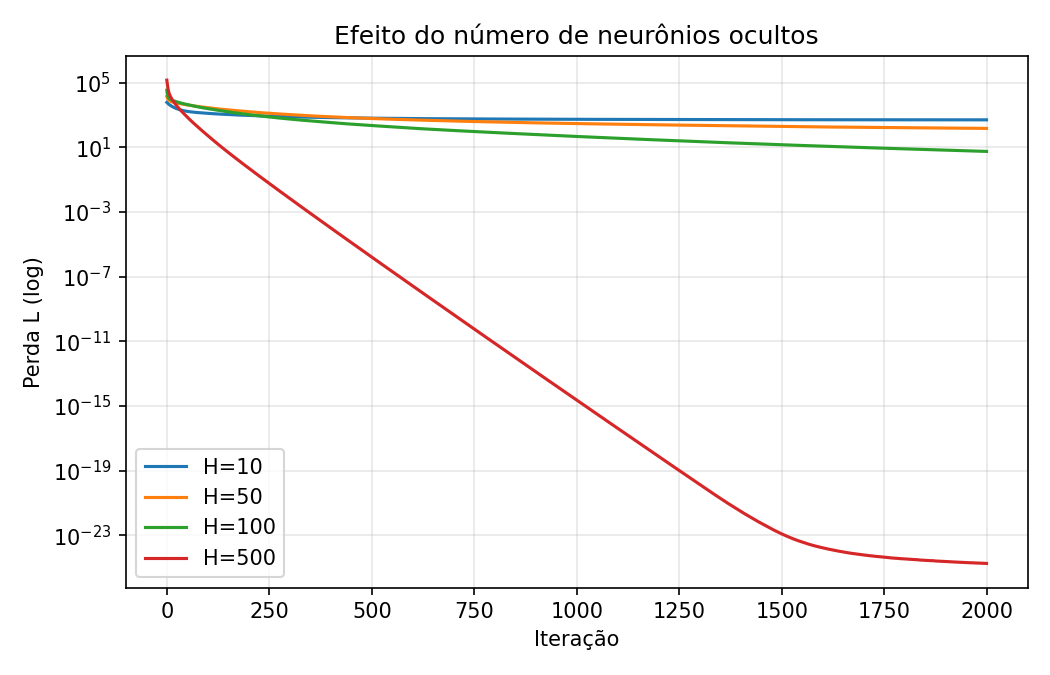

In [ ]:
from IPython.display import Image, display
for i in ["1_perda", "2_norma_gradientes", "3_histograma_h", "4_taxas_aprendizado", "5_tamanho_H"]:
  display(Image(f"resultados/fig{i}.png"))

In [ ]:
!zip -r resultados.zip resultados
from google.colab import files
files.download("resultados.zip")

updating: resultados/ (stored 0%)
updating: resultados/resultados.json (deflated 67%)
updating: resultados/fig3_histograma_h.png (deflated 26%)
updating: resultados/fig5_tamanho_H.png (deflated 10%)
updating: resultados/fig2_norma_gradientes.png (deflated 8%)
updating: resultados/fig1_perda.png (deflated 14%)
updating: resultados/fig4_taxas_aprendizado.png (deflated 10%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>